# Лабораторная работа №2. Вариант 3

Область: Экология и мониторинг среды.

Датасет: Air Quality Data in India (`real_2013.csv`).

Случайная величина: концентрация микрочастиц PM2.5.

Прикладной вопрос: Какова вероятность, что в случайный день уровень загрязнения превысит норму ВОЗ?

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

WHO_NORM = 15

## Задание 1

Объем выборки (n): 177
Интервалов по Стерджесу: 9


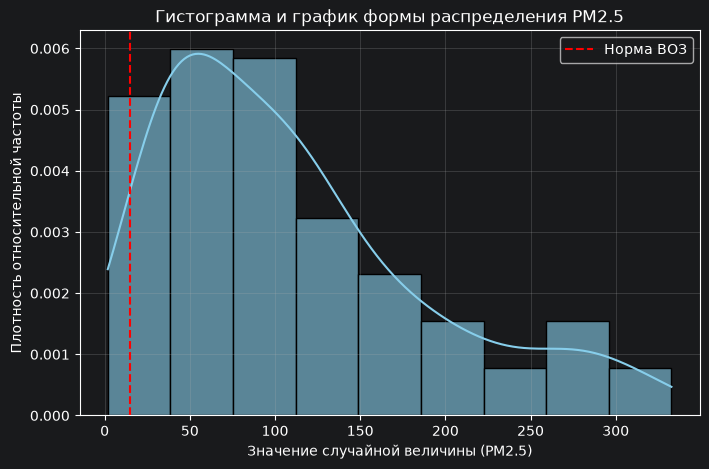

In [61]:
df = pd.read_csv('real_2013.csv')

X = df['PM 2.5'].dropna()
X = X[X > 0].values

n = len(X)
print(f'Объем выборки (n): {n}')

L = int(np.ceil(1 + np.log2(n)))
print(f'Интервалов по Стерджесу: {L}')

plt.figure(figsize=(8, 5))
sns.histplot(X, bins=L, stat='density', edgecolor='black', alpha=0.6, color='skyblue', kde=True)
plt.axvline(WHO_NORM, color='red', ls='--', label='Норма ВОЗ')
plt.title('Гистограмма и график формы распределения PM2.5')
plt.xlabel('Значение случайной величины (PM2.5)')
plt.ylabel('Плотность относительной частоты')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Почти все значения больше нормы ВОЗ.

## Задание 2

In [62]:
def calculate_custom_stats(arr):
    n_elem = len(arr)
    mean_val = np.sum(arr) / n_elem
    variance_val = np.sum((arr - mean_val) ** 2) / (n_elem - 1)
    m3 = np.sum((arr - mean_val) ** 3) / n_elem
    m4 = np.sum((arr - mean_val) ** 4) / n_elem
    std_empirical = np.sqrt(np.sum((arr - mean_val) ** 2) / n_elem)
    skewness_val = m3 / (std_empirical ** 3)
    kurtosis_val = (m4 / (std_empirical ** 2) ** 2) - 3
    return mean_val, variance_val, skewness_val, kurtosis_val

c_mean, c_var, c_skew, c_kurt = calculate_custom_stats(X)
print(f'[Кастомные расчеты]: M(X)={c_mean:.2f}, D(X)={c_var:.2f}, A={c_skew:.2f}, E={c_kurt:.2f}')
print(f'[Методы Pandas]: M(X)={pd.Series(X).mean():.2f}, D(X)={pd.Series(X).var():.2f}, A={pd.Series(X).skew():.2f}, E={pd.Series(X).kurt():.2f}')

[Кастомные расчеты]: M(X)=109.48, D(X)=6160.69, A=1.03, E=0.30
[Методы Pandas]: M(X)=109.48, D(X)=6160.69, A=1.04, E=0.35


Мат. ожидание и дисперсия совпадают. A и E чу-чуть отличаются, потому что pandas считает их с поправкой на смещение.

## Задание 3

In [63]:
alpha = 0.05
chi2_stat, p_val = stats.normaltest(X)
print(f'Статистика критерия: {chi2_stat:.4f}, p-value: {p_val}')
if p_val < alpha:
    print('Вывод: Гипотеза H0 о нормальности ОТВЕРГАЕТСЯ.')
else:
    print('Вывод: Гипотеза H0 о нормальности ПРИНИМАЕТСЯ.')

Статистика критерия: 25.3861, p-value: 3.0723742790218407e-06
Вывод: Гипотеза H0 о нормальности ОТВЕРГАЕТСЯ.


## Прикладной вопрос

In [72]:
p_empirical = np.mean(X > WHO_NORM)
print(f'P(X > {WHO_NORM}) = {p_empirical:.3f}')

P(X > 15) = 0.989


**Вывод:** норма ВОЗ превышается с вероятностью = 0.99, то есть почти каждый день.